# PVSPICE potential-induced-degradation simulation using Pingel patterns

This example simulates a 12-module string of half-cut PV modules with spatially varying shunt resistance. It reproduces the relative shunt-resistance exposure values and five affected-module patterns extracted from the supplied exploratory notebook, which attributes the patterns to S. Pingel et al., Potential Induced Degradation of Solar Cells and Panels, 35th IEEE PVSC, 2010, DOI 10.1109/PVSC.2010.5616823.

The pattern is an illustrative transcription, not a fitted prediction for a specific module product. The electrical baseline is deliberately synthetic so the notebook runs without proprietary measurements.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import os

def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file():
            return candidate
    raise FileNotFoundError('Run this notebook from within a pvcracks checkout.')

project_root = find_project_root(Path.cwd().resolve())
os.chdir(project_root)

output_dir = project_root / 'docs' / 'data' / 'pid_pingle_example'
output_dir.mkdir(parents=True, exist_ok=True)

from pvcracks.pvspice import (
    modules_halfcut_netlist_builder,
    ngpsice_read_voltage_current_modules,
    run_ngspice,
)

# Pingel-style PID data and helpers are local to this worked example.
PINGEL_PID_REMAINING_SHUNT_FRACTIONS = {
    0: 1.0,
    40: 0.6355,
    80: 0.0062,
    100: 0.0025,
}

PINGEL_PID_PATTERNS = (
    (
        (0, 0, 16), (1, 0, 3), (1, 8, 14), (2, 0, 6), (3, 0, 3),
        (4, 0, 2), (5, 0, 6), (5, 20, 22), (0, 20, 22),
    ),
    ((0, 0, 22), (1, 0, 4), (2, 0, 3), (3, 0, 7), (4, 0, 2), (5, 0, 7)),
    ((1, 0, 7), (3, 0, 5), (5, 0, 8), (5, 20, 22)),
    ((0, 0, 8), (1, 0, 6), (2, 0, 3), (3, 0, 5), (4, 0, 3), (5, 0, 3), (0, 20, 22)),
    ((0, 0, 4), (0, 7, 9), (0, 12, 16), (1, 0, 2), (2, 0, 2), (5, 0, 1)),
)

def apply_pingle_pid_pattern(
    healthy_shunt_resistance, exposure_hours, *, pattern_index=0, rows=6, columns=22
):
    '''Create one Pingel-style 6 by 22 PID shunt-resistance map.'''
    if healthy_shunt_resistance <= 0:
        raise ValueError('healthy_shunt_resistance must be positive.')
    if exposure_hours not in PINGEL_PID_REMAINING_SHUNT_FRACTIONS:
        raise ValueError('exposure_hours must be one of 0, 40, 80, or 100.')
    if (rows, columns) != (6, 22):
        raise ValueError('Pingel PID patterns are defined for a 6 by 22 layout.')
    if not 0 <= pattern_index < len(PINGEL_PID_PATTERNS):
        raise ValueError(
            f'pattern_index must be between 0 and {len(PINGEL_PID_PATTERNS) - 1}.'
        )
    result = np.full((rows, columns), healthy_shunt_resistance, dtype=float)
    degraded = healthy_shunt_resistance * PINGEL_PID_REMAINING_SHUNT_FRACTIONS[exposure_hours]
    for row, start, stop in PINGEL_PID_PATTERNS[pattern_index]:
        result[row, start:stop] = degraded
    return result.ravel()


def build_pingle_pid_string(
    healthy_shunt_resistance, exposure_hours, *, modules=12, affected_modules=5
):
    '''Return full-string half-cell shunt resistances for this Pingel-style case.'''
    if modules <= 0 or not 0 <= affected_modules <= modules:
        raise ValueError('affected_modules must be between 0 and modules.')
    maps = [
        apply_pingle_pid_pattern(
            healthy_shunt_resistance,
            exposure_hours,
            pattern_index=min(index, len(PINGEL_PID_PATTERNS) - 1),
        )
        for index in range(affected_modules)
    ]
    maps.extend(
        np.full(6 * 22, healthy_shunt_resistance, dtype=float)
        for _ in range(modules - affected_modules)
    )
    return np.concatenate(maps)

# Set this to the exact ngspice executable installed in your environment.
# Linux example: Path('/usr/bin/ngspice')
# Windows example: Path(r'C:/Program Files/ngspice-47_64/Spice64/bin/ngspice.exe')
ngspice_path = Path('/absolute/path/to/ngspice')
if not ngspice_path.is_file():
    raise FileNotFoundError('Set ngspice_path to your ngspice executable before running this notebook.')
print(f'Project root: {project_root}')
print(f'ngspice: {ngspice_path}')

## Synthetic half-cut module baseline

Each module has 132 half cells arranged in a 6 by 22 map. The parameters below are illustrative and are intentionally kept in one cell so users can replace them with parameters derived from a measured module.

In [2]:
N_S = 132
N_MODULES = 12
N_BYPASS = 3
AFFECTED_MODULES = 5

# Synthetic electrical baseline for one half cell.
IPH = 5.0
RS = 0.02
HEALTHY_RSH = 50.0
IDEALITY_FACTOR = 1.2
SATURATION_CURRENT = 5e-10
BREAKDOWN_VOLTAGE = 25.0
BYPASS_BREAKDOWN_VOLTAGE = 23.0
MODULE_VOC = 48.0
TEMPERATURE_C = 25.0
VOLTAGE_STEP = 5.0

exposure_hours = tuple(PINGEL_PID_REMAINING_SHUNT_FRACTIONS)
pd.DataFrame({
    'Exposure (h)': exposure_hours,
    'Remaining affected-cell Rsh fraction': [
        PINGEL_PID_REMAINING_SHUNT_FRACTIONS[hour] for hour in exposure_hours
    ],
    'Affected-cell Rsh (ohm)': [
        HEALTHY_RSH * PINGEL_PID_REMAINING_SHUNT_FRACTIONS[hour]
        for hour in exposure_hours
    ],
})

,Exposure (h),Remaining affected-cell Rsh fraction,Affected-cell Rsh (ohm)
0,0,1.0000,50.000
1,40,0.6355,31.775
2,80,0.0062,0.310
3,100,0.0025,0.125


## Spatial PID patterns

The five maps below represent the affected modules in the first part of the string. Healthy cells retain the baseline shunt resistance; highlighted cells use the exposure-dependent reduced shunt resistance.

Text(0.5, 0.98, 'Pingel-style PID patterns at 100 h')

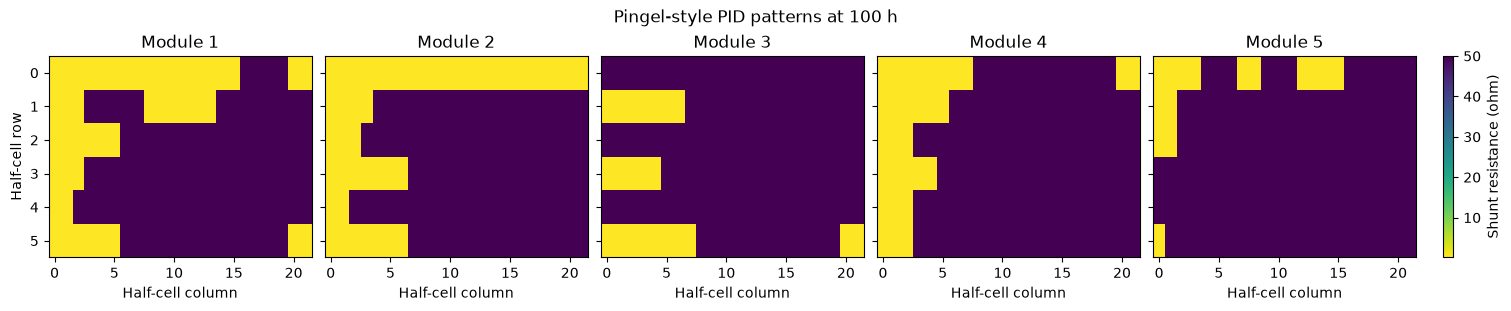

In [6]:
fig, axes = plt.subplots(
    1,
    AFFECTED_MODULES,
    figsize=(15, 3),
    sharey=True,
    layout="constrained",
)

for module_index, axis in enumerate(axes):
    shunt_map = apply_pingle_pid_pattern(
        HEALTHY_RSH, 100, pattern_index=module_index
    ).reshape(6, 22)

    image = axis.imshow(shunt_map, cmap="viridis_r", aspect="auto")
    axis.set_title(f"Module {module_index + 1}")
    axis.set_xlabel("Half-cell column")

axes[0].set_ylabel("Half-cell row")

colorbar = fig.colorbar(
    image,
    ax=axes,
    location="right",
    pad=0.02,
    label="Shunt resistance (ohm)",
)

fig.suptitle("Pingel-style PID patterns at 100 h")

## Simulate the 12-module string

For each exposure time, pvspice writes an inspectable netlist, runs ngspice, and reads the source current from the named raw-file columns. The result table reports the maximum sampled power; decrease VOLTAGE_STEP for a finer sweep.

In [4]:
curves = {}
summary = []

for hours in exposure_hours:
    circuit_name = f'pid_pingle_{hours:03d}h'
    shunt_resistances = build_pingle_pid_string(
        HEALTHY_RSH,
        hours,
        modules=N_MODULES,
        affected_modules=AFFECTED_MODULES,
    )
    modules_halfcut_netlist_builder(
        path=output_dir,
        N_s=N_S,
        N_modules=N_MODULES,
        cell_currents_=IPH,
        series_resistances_=RS,
        shunt_resistances_=shunt_resistances,
        ideality_factor=IDEALITY_FACTOR,
        saturation_current=SATURATION_CURRENT,
        breakdown_voltage=BREAKDOWN_VOLTAGE,
        v_bypass=BYPASS_BREAKDOWN_VOLTAGE,
        v_oc=MODULE_VOC,
        N_byp=N_BYPASS,
        TNOM=TEMPERATURE_C,
        circuit_name=circuit_name,
        v_step=VOLTAGE_STEP,
    )
    run_ngspice(ngspice_path, output_dir / f'{circuit_name}.cir', timeout=120)
    _, _, curve = ngpsice_read_voltage_current_modules(
        output_dir, f'{circuit_name}.out'
    )
    curve = curve.copy()
    if curve.loc[curve['V'].abs().idxmin(), 'I'] < 0:
        curve['I'] = -curve['I']
    curve['P'] = curve['V'] * curve['I']
    maximum_power_index = curve['P'].idxmax()
    curves[hours] = curve
    summary.append({
        'Exposure (h)': hours,
        'Pmpp (W)': curve.loc[maximum_power_index, 'P'],
        'Vmpp (V)': curve.loc[maximum_power_index, 'V'],
        'Impp (A)': curve.loc[maximum_power_index, 'I'],
    })

summary = pd.DataFrame(summary)
summary['Power loss (%)'] = 100 * (1 - summary['Pmpp (W)'] / summary.loc[0, 'Pmpp (W)'])
summary.to_csv(output_dir / 'pid_pingle_summary.csv', index=False)
summary

,Exposure (h),Pmpp (W),Vmpp (V),Impp (A),Power loss (%)
0,0,3934.307097,420.0,9.367398,0.000000
1,40,3933.802008,420.0,9.366195,0.012838
2,80,3569.215610,400.0,8.923039,9.279690
3,100,3449.114938,385.0,8.958740,12.332341


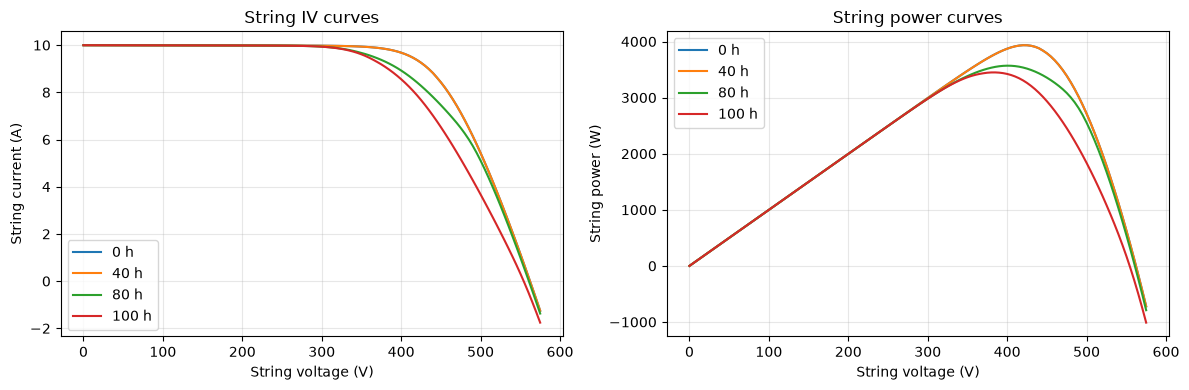

In [5]:
fig, (iv_axis, power_axis) = plt.subplots(1, 2, figsize=(12, 4))
for hours, curve in curves.items():
    iv_axis.plot(curve['V'], curve['I'], label=f'{hours} h')
    power_axis.plot(curve['V'], curve['P'], label=f'{hours} h')
iv_axis.set(xlabel='String voltage (V)', ylabel='String current (A)', title='String IV curves')
power_axis.set(xlabel='String voltage (V)', ylabel='String power (W)', title='String power curves')
for axis in (iv_axis, power_axis):
    axis.grid(alpha=0.3)
    axis.legend()
fig.tight_layout()

The generated netlists and CSV summary are stored in docs/data/pid_pingle_example. They are derived outputs and are intentionally not required as repository inputs.